# Chapitre 6 - Cours 3 : Un RAG de bout en bout, et au-delà du texte

Les cours 1 et 2 ont construit et optimisé le retriever. Branchons-le maintenant sur un
générateur (Qwen2.5-0.5B-Instruct) et mesurons ce que le RAG change réellement aux réponses.
On termine par la section *RAG Beyond Texts* : RAG sur des données tabulaires (text-to-SQL) et
RAG multimodal.

Plan :

1. assembler un RAG complet (recherche hybride, reranking, prompt, génération) ;
2. avec ou sans contexte : mesurer l'apport du RAG, l'abstention et les hallucinations ;
3. évaluer composant par composant : erreurs du retriever ou du générateur ?
4. combien de passages donner, et où placer le bon ?
5. RAG sur données tabulaires : text-to-SQL sur une base de ventes ;
6. RAG multimodal.

In [1]:
import os

os.environ["HF_HUB_OFFLINE"] = "1"          # modèles déjà en cache : aucun appel réseau
os.environ["HF_HUB_VERBOSITY"] = "error"
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aie import llm
from aie import ch06_rag_agents as c6
from aie.diagrams import Diagram
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

set_style()
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 120)
P = c6.passages()
TEXTS, IDS = [p.text for p in P], [p.pid for p in P]
TXT = dict(zip(IDS, TEXTS))
Q = c6.QUESTIONS
tok, _ = llm.load(llm.SMALL)
ntok_msgs = lambda m: len(tok.apply_chat_template(m, tokenize=True, return_dict=True)["input_ids"])  # noqa: E731

## 1. Assembler un RAG complet (section *RAG Architecture*)

Notre pipeline reprend les meilleurs choix du cours 2 :

1. **recherche hybride** : BM25 et embeddings multilingues, top-20 chacun, fusion RRF ;
2. **reranking** des 20 candidats par le cross-encoder `bge-reranker-v2-m3` ;
3. **prompt** : consigne système (répondre à partir des documents, sinon dire « Je ne sais
   pas »), puis les $k$ passages numérotés, puis la question ;
4. **génération** gloutonne par Qwen2.5-0.5B-Instruct (température 0, donc déterministe).

Le livre note que l'article original entraînait retriever et générateur ensemble ; nous
assemblons, comme la plupart des équipes, des composants pré-entraînés séparément.

In [2]:
bm25 = c6.TermRetriever(TEXTS, IDS)
dense = c6.DenseRetriever(TEXTS, IDS)

def retrieve(question, k=3, rerank=True):
    cand = [d_ for d_, _ in c6.rrf([bm25.search(question, 20), dense.search(question, 20)])][:20]
    if rerank:
        s = c6.cross_encoder_scores(question, [TXT[d_] for d_ in cand])
        cand = [cand[i] for i in np.argsort(-s, kind="stable")]
    return cand[:k]

def rag_messages(question, contexts):
    if contexts is None:  # pas de RAG : le modèle répond de mémoire
        return [{"role": "system", "content": "Tu réponds en français, en une ou deux phrases."},
                {"role": "user", "content": question}]
    return [{"role": "system", "content": c6.RAG_SYSTEM}, {"role": "user", "content": c6.build_rag_prompt(question, contexts)}]

q0 = Q[4]["question"]
ctx0 = retrieve(q0)
msgs0 = rag_messages(q0, [TXT[d_] for d_ in ctx0])
print("Passages retenus :", ctx0)
print("-" * 100)
print(msgs0[1]["content"][:900], "...")
print("-" * 100)
print("Réponse :", c6.generate_batch([msgs0], max_new_tokens=48)[0])

Passages retenus : ['thermo-8', 'thermo-1', 'rh-4']
----------------------------------------------------------------------------------------------------
Documents :
[Document 1]
Le Thermo-X200 est garanti trois ans à compter de la date d'achat, sur présentation de la facture. La garantie ne couvre pas les dommages causés par une installation non conforme ou par une surtension. Une extension de garantie de deux années supplémentaires peut être souscrite en ligne.

[Document 2]
Le Thermo-X200 est un thermostat connecté conçu par la société Domotik pour les maisons équipées d'une chaudière ou d'une pompe à chaleur. Il mesure la température toutes les trente secondes et ajuste le chauffage pièce par pièce. Son écran tactile de 3,5 pouces affiche la consigne et la consommation du jour.

[Document 3]
La période d'essai dure deux mois pour les employés et quatre mois pour les cadres. Elle peut être renouvelée une fois, avec l'accord écrit du salarié. Pendant cette période, chaque partie peut 

Réponse : Trois ans.


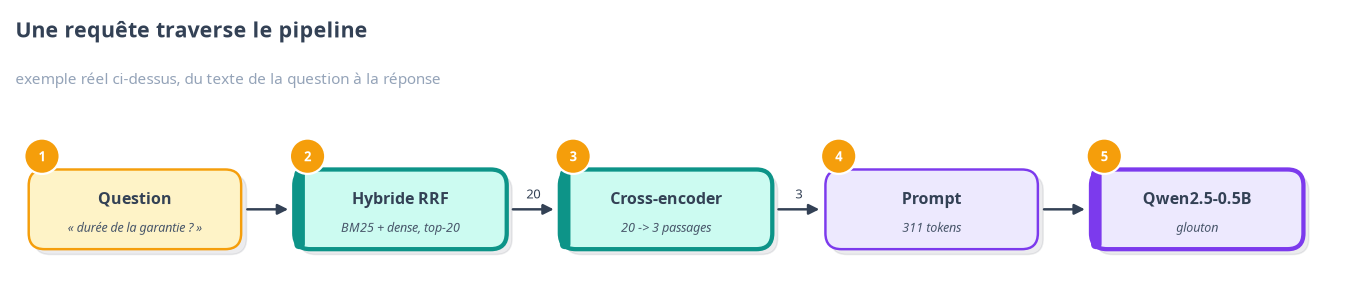

In [3]:
d = Diagram(15, 2.2, title="Une requête traverse le pipeline", subtitle="exemple réel ci-dessus, du texte de la question à la réponse")
d.box("q", 1.4, 0.9, "Question", sub="« durée de la garantie ? »", color=AMBER, w=2.4)
d.box("hyb", 4.4, 0.9, "Hybride RRF", sub="BM25 + dense, top-20", color=TEAL, w=2.4, kind="model")
d.box("ce", 7.4, 0.9, "Cross-encoder", sub="20 -> 3 passages", color=TEAL, w=2.4, kind="model")
d.box("pr", 10.4, 0.9, "Prompt", sub=f"{ntok_msgs(msgs0)} tokens", color=VIOLET, w=2.4)
d.box("gen", 13.4, 0.9, "Qwen2.5-0.5B", sub="glouton", color=VIOLET, kind="model", w=2.4)
for a, b, lab in [("q", "hyb", None), ("hyb", "ce", "20"), ("ce", "pr", "3"), ("pr", "gen", None)]:
    d.arrow(a, b, lab)
for i, x in enumerate([1.4, 4.4, 7.4, 10.4, 13.4], start=1):
    d.badge(x - 1.05, 1.5, str(i))
d.show()

> **À retenir.** Un RAG complet tient en une dizaine de lignes : recherche, reranking,
> gabarit de prompt, génération. Toute la difficulté est dans la qualité de chaque étage et
> dans la façon de les évaluer.

## 2. Avec ou sans contexte (section *RAG*)

Lewis et al. (2020) ont montré qu'un accès à l'information pertinente rend les réponses plus
précises et réduit les hallucinations. Vérifions-le sur nos 42 questions, dans quatre
conditions :

- **sans contexte** : le modèle répond de mémoire ;
- **RAG** : les 3 passages du pipeline ;
- **oracle** : uniquement le passage pertinent annoté (borne haute pour le générateur) ;
- **hors sujet** : 3 passages tirés au hasard parmi les non pertinents (le bon comportement est
  alors de répondre « Je ne sais pas »).

Une réponse est jugée correcte si elle contient l'une des variantes attendues (par exemple «
25 » pour les congés). C'est un juge grossier mais transparent ; les chapitres 3 et 4 discutent
de juges plus fins.

168 générations en 16 s


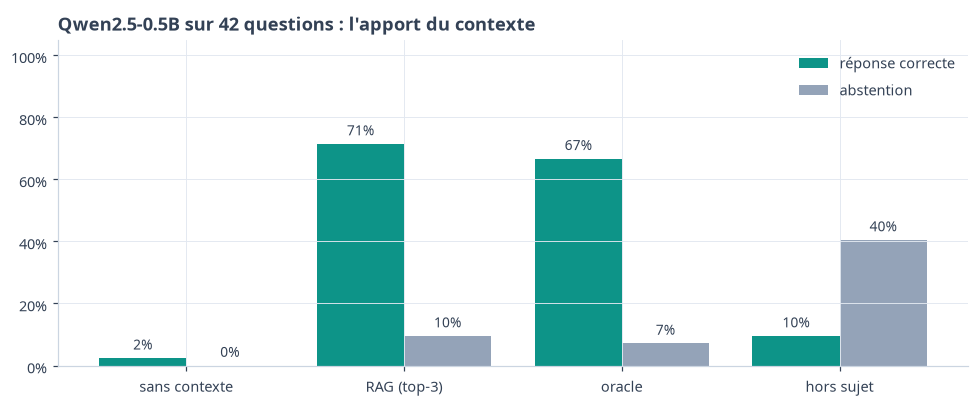

,exactitude,abstention (« Je ne sais pas »)
sans contexte,0.024,0.000
RAG (top-3),0.714,0.095
oracle,0.667,0.071
hors sujet,0.095,0.405


In [4]:
rng = np.random.default_rng(0)
top3 = {q["qid"]: retrieve(q["question"], 3) for q in Q}
conditions = {
    "sans contexte": [rag_messages(q["question"], None) for q in Q],
    "RAG (top-3)": [rag_messages(q["question"], [TXT[d_] for d_ in top3[q["qid"]]]) for q in Q],
    "oracle": [rag_messages(q["question"], [TXT[max(q["relevant"], key=q["relevant"].get)]]) for q in Q],
    "hors sujet": [rag_messages(q["question"], [TXT[d_] for d_ in rng.choice([i for i in IDS if i not in q["relevant"]], 3, replace=False)])
                   for q in Q],
}
t = time.perf_counter()
reponses = {c: c6.generate_batch(m, max_new_tokens=48) for c, m in conditions.items()}
print(f"{4 * len(Q)} générations en {time.perf_counter() - t:.0f} s")
res = pd.DataFrame({c: {"exactitude": np.mean([c6.answer_ok(a, q["answers"]) for a, q in zip(r, Q)]),
                        "abstention (« Je ne sais pas »)": np.mean([c6.abstains(a) for a in r])}
                    for c, r in reponses.items()}).T

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(res))
ax.bar(x - 0.2, res["exactitude"], 0.4, color=TEAL, label="réponse correcte")
ax.bar(x + 0.2, res["abstention (« Je ne sais pas »)"], 0.4, color=GRAY, label="abstention")
annotate_bars(ax, "{:.0%}")
ax.set_xticks(x); ax.set_xticklabels(res.index); ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Qwen2.5-0.5B sur 42 questions : l'apport du contexte"); ax.legend()
plt.tight_layout(); plt.show()
res.round(3)

In [5]:
choix = [4, 7, 12, 28, 31, 32]
pd.DataFrame([{"question": Q[i]["question"], "sans contexte": reponses["sans contexte"][i][:110],
               "RAG": reponses["RAG (top-3)"][i][:110]} for i in choix])

,question,sans contexte,RAG
0,Quelle est la durée de la garantie du Thermo-X200 ?,La garantie Thermo-X200 est de 1 an.,Trois ans.
1,Combien de jours de vacances ai-je par an chez Calypso ?,Calypso propose des vacances d'été pour 10 jours par an.,Je ne sais pas.
2,Quel montant puis-je dépenser pour me former chaque année ?,"Pour déterminer le montant de votre formation annuelle, il vous faudra :\n\n1. Évaluer vos besoins spécifiques (",Je ne sais pas.
3,Combien de temps la lumière solaire met-elle à nous parvenir ?,La lumière solaire se déplace à travers l'air et atteint notre planète environ 90 minutes.,Huit minutes et vingt secondes.
4,Combien coûte le Fedora Fruité ?,Le coût exact de l'installation et de la mise à jour du système d'exploitation Fedora Fruite varie selon les m,18 euros
5,À partir de quel montant la livraison est-elle gratuite chez Minou Chic ?,La livraison est gratuite chez Minou Chic pour tout achat de plus de 100€.,De 50 euros jusqu'à 100 points.


Sans contexte, le modèle ne peut pas connaître les faits fictifs (prix de Minou Chic, règles
RH de Calypso, codes du Thermo-X200) : il **invente** avec aplomb une garantie, un prix, un
plafond. Avec le contexte, l'exactitude bondit. Surprise : l'« oracle » (le seul passage
annoté) ne fait pas mieux que le RAG à 3 passages. Les deux conditions diffèrent de quelques
questions seulement, et les passages voisins du même document aident parfois le petit modèle
à comprendre de quoi parle le passage clé. L'écart entre ces deux conditions et 100 % est la part
du **générateur** : un modèle de 0,5 milliard de paramètres lit mal certains passages ou
répond « Je ne sais pas » alors que la réponse est là (par exemple, il ne relie pas
« vacances » à « congés payés »). Avec des passages hors sujet, il s'abstient souvent (c'est le comportement
demandé), mais pas toujours : il lui arrive d'inventer malgré la consigne.

> **À retenir.** Le RAG transforme un modèle qui hallucine en un modèle qui **lit** : sur des
> faits absents des données d'entraînement, c'est la seule façon d'obtenir des réponses
> justes. La condition « hors sujet » mesure la capacité à **s'abstenir**, aussi importante
> que l'exactitude.

## 3. Évaluer composant par composant (section *Retrieval Algorithms*)

Le livre recommande d'évaluer un RAG **par composant** (qualité de la recherche, des
embeddings) **et de bout en bout** (qualité des réponses). Croisons les deux pour chaque
question : le bon passage figurait-il dans le top-3 ? la réponse est-elle correcte ? Les quatre
cases ne demandent pas la même correction.

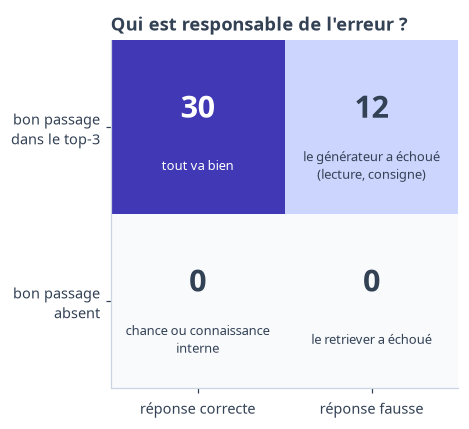

,question,attendu,réponse RAG
0,Que signifie le code E-42 sur le Thermo-X200 ?,sonde,Le code E-42 signifie que le Thermo-X200 a été mis en œuvre avec une fonctionnalité de surveillance thermique intégrée.
1,"Mon thermostat affiche que les piles sont faibles, que faire ?",AAA,Remplissez les piles avec des batteries.
2,Combien de jours de vacances ai-je par an chez Calypso ?,25,Je ne sais pas.
3,Combien de jours par semaine puis-je travailler depuis chez moi ?,trois,Je ne sais pas.
4,Quel montant puis-je dépenser pour me former chaque année ?,1 500,Je ne sais pas.


In [6]:
hit = np.array([any(d_ in q["relevant"] for d_ in top3[q["qid"]]) for q in Q])
ok = np.array([c6.answer_ok(a, q["answers"]) for a, q in zip(reponses["RAG (top-3)"], Q)])
M = np.array([[np.sum(hit & ok), np.sum(hit & ~ok)], [np.sum(~hit & ok), np.sum(~hit & ~ok)]])
fig, ax = plt.subplots(figsize=(6.8, 4))
ax.imshow(M, cmap="aie_seq", vmin=0, vmax=M.max() * 1.3)
labels = [["tout va bien", "le générateur a échoué\n(lecture, consigne)"],
          ["chance ou connaissance\ninterne", "le retriever a échoué"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i - 0.12, str(M[i, j]), ha="center", va="center", fontsize=20, fontweight="bold",
                color="white" if M[i, j] > M.max() * 0.65 else SLATE)
        ax.text(j, i + 0.22, labels[i][j], ha="center", va="center", fontsize=8.5,
                color="white" if M[i, j] > M.max() * 0.65 else SLATE)
ax.set_xticks([0, 1]); ax.set_xticklabels(["réponse correcte", "réponse fausse"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["bon passage\ndans le top-3", "bon passage\nabsent"])
ax.grid(False); ax.set_title("Qui est responsable de l'erreur ?")
plt.tight_layout(); plt.show()
fails = [q for q, h, o in zip(Q, hit, ok) if h and not o][:5]
pd.DataFrame([{"question": q["question"], "attendu": q["answers"][0],
               "réponse RAG": reponses["RAG (top-3)"][Q.index(q)][:120]} for q in fails])

Grâce au cross-encoder, le retriever ne rate presque rien : l'essentiel des erreurs vient du
**générateur**, qui avait le bon passage sous les yeux. Lire ces cas est instructif : réponses
partielles, confusion entre deux passages voisins, abstention injustifiée, ou réponse correcte
formulée autrement que nos variantes attendues (une limite de notre juge par sous-chaîne).
Améliorer encore le retriever ne servirait donc à rien ici : il faudrait un meilleur
générateur, un meilleur prompt, ou un juge plus fin.

> **À retenir.** Croiser « le bon passage a-t-il été récupéré ? » et « la réponse est-elle
> correcte ? » indique **quel composant** améliorer. Un RAG s'évalue par composant **et** de
> bout en bout.

## 4. Combien de passages, et où placer le bon ? (sections *RAG* et *Reranking*)

Plus de passages augmentent la probabilité d'inclure le bon (rappel), mais aussi le coût et le
bruit. Le livre rappelle (section *Context Length and Context Efficiency*, chapitre 5) qu'un
modèle exploite mieux le début et la fin du contexte. Deux expériences :

1. faire varier $k$ (nombre de passages du pipeline) et mesurer exactitude et tokens ;
2. noyer le bon passage parmi 6 passages hors sujet et faire varier sa **position**.

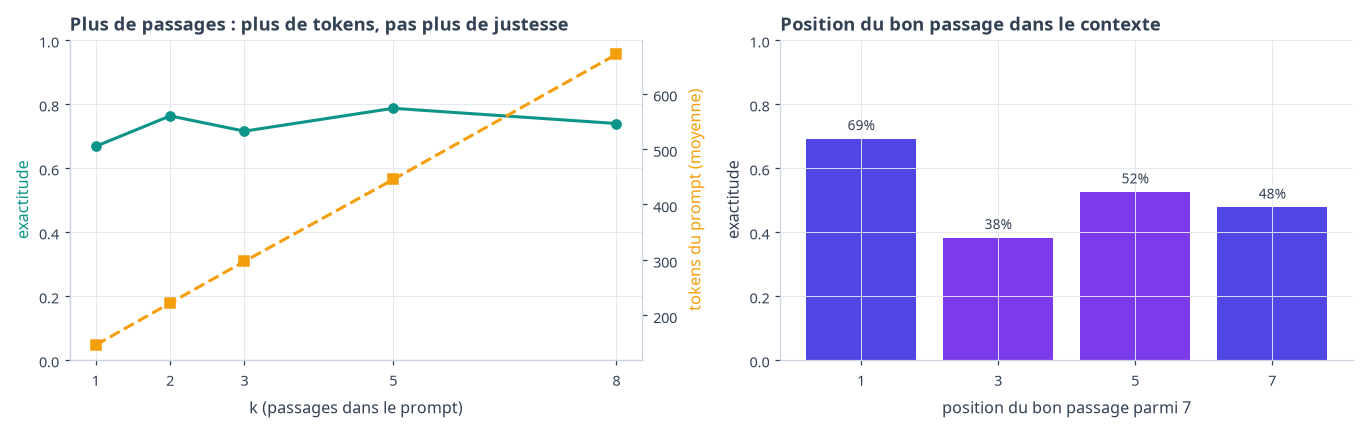

In [7]:
ks = [1, 2, 3, 5, 8]
top8 = {q["qid"]: retrieve(q["question"], 8) for q in Q}
acc_k, tok_k = [], []
for k in ks:
    m = [rag_messages(q["question"], [TXT[d_] for d_ in top8[q["qid"]][:k]]) for q in Q]
    r = c6.generate_batch(m, max_new_tokens=48)
    acc_k.append(np.mean([c6.answer_ok(a, q["answers"]) for a, q in zip(r, Q)]))
    tok_k.append(np.mean([ntok_msgs(x) for x in m]))

positions = [0, 2, 4, 6]
acc_pos = []
for pos in positions:
    m = []
    for q in Q:
        gold = max(q["relevant"], key=q["relevant"].get)
        bruit = list(rng.choice([i for i in IDS if i not in q["relevant"]], 6, replace=False))
        docs = bruit[:pos] + [gold] + bruit[pos:]
        m.append(rag_messages(q["question"], [TXT[d_] for d_ in docs]))
    r = c6.generate_batch(m, max_new_tokens=48, batch_size=12)
    acc_pos.append(np.mean([c6.answer_ok(a, q["answers"]) for a, q in zip(r, Q)]))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
ax = axes[0]
ax.plot(ks, acc_k, marker="o", color=TEAL, label="exactitude")
ax.set_xlabel("k (passages dans le prompt)"); ax.set_ylabel("exactitude", color=TEAL)
ax.set_ylim(0, 1); ax.set_xticks(ks)
ax2 = ax.twinx(); ax2.plot(ks, tok_k, marker="s", color=AMBER, ls="--", label="tokens"); ax2.grid(False)
ax2.set_ylabel("tokens du prompt (moyenne)", color=AMBER); ax2.spines["right"].set_visible(True)
ax.set_title("Plus de passages : plus de tokens, pas plus de justesse")
ax = axes[1]
ax.bar([str(p + 1) for p in positions], acc_pos, color=[INDIGO, VIOLET, VIOLET, INDIGO])
annotate_bars(ax, "{:.0%}")
ax.set_xlabel("position du bon passage parmi 7"); ax.set_ylabel("exactitude"); ax.set_ylim(0, 1)
ax.set_title("Position du bon passage dans le contexte")
finish(fig); plt.show()

Le coût en tokens croît linéairement avec $k$, alors que l'exactitude plafonne vite : notre
reranker place déjà le bon passage en tête, et chaque passage supplémentaire est surtout du
bruit qu'un petit modèle doit ignorer. La position du bon passage pèse beaucoup plus lourd
pour ce petit modèle : en tête de contexte, il est bien mieux exploité qu'au milieu, et la
fin ne rattrape qu'une partie de l'écart (avec 42 questions, chaque point vaut environ 2,4 %,
mais l'écart entre la première position et le milieu dépasse largement ce bruit). C'est le
phénomène « perdu au milieu » évoqué au chapitre 5. D'où deux pratiques : **reranker pour
réduire $k$**, et placer les passages les plus pertinents en tête (ou en fin) de contexte.

> **À retenir.** Choisir $k$ par la mesure : au-delà du point où le rappel sature, chaque
> passage ajoute du coût et du bruit. L'ordre des passages compte moins qu'en recherche Web,
> mais il compte.

## 5. RAG sur données tabulaires (section *RAG with tabular data*)

Beaucoup de questions portent sur des **tables** : « Combien d'unités de Fedora Fruité
avons-nous vendues ? ». On ne « recherche » pas de passage : on **génère une requête SQL**, on
l'exécute, puis on rédige la réponse à partir du résultat. Le livre prend l'exemple d'une
boutique fictive de mode pour chats ; nous construisons la nôtre (Minou Chic) dans SQLite :
une table `produits` et une table `ventes` de 300 commandes.

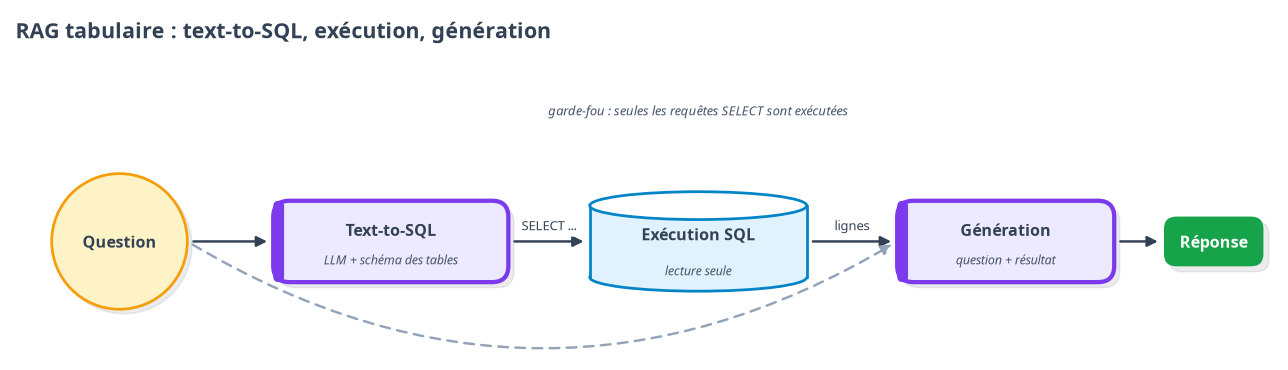

Table produits(id INTEGER, nom TEXT, prix REAL)
Table ventes(id INTEGER, date TEXT au format AAAA-MM-JJ, produit_id INTEGER, quantite INTEGER)
ventes.produit_id fait référence à produits.id


,id,date,nom,prix,quantite
0,1,2026-11-13,Fedora Fruité,18.0,2
1,2,2026-09-27,Fedora Fruité,18.0,1
2,3,2026-09-16,Pull Torsadé,24.0,3
3,4,2026-10-14,Collier Lumineux,9.5,2
4,5,2026-10-25,Pull Torsadé,24.0,2


In [8]:
d = Diagram(14, 3.3, title="RAG tabulaire : text-to-SQL, exécution, génération")
d.box("q", 1.2, 1.3, "Question", color=AMBER, kind="user", w=1.5)
d.box("sql", 4.2, 1.3, "Text-to-SQL", sub="LLM + schéma des tables", color=VIOLET, kind="model", w=2.6)
d.box("db", 7.6, 1.3, "Exécution SQL", sub="lecture seule", color=SKY, kind="db", w=2.4, h=1.1)
d.box("gen", 11.0, 1.3, "Génération", sub="question + résultat", color=VIOLET, kind="model", w=2.4)
d.box("ans", 13.3, 1.3, "Réponse", color=GREEN, kind="tag", w=1.1, h=0.55)
d.arrow("q", "sql"); d.arrow("sql", "db", "SELECT ..."); d.arrow("db", "gen", "lignes"); d.arrow("gen", "ans")
d.arrow("q", "gen", style="dashed", rad=0.3, color=GRAY)
d.note(7.6, 2.75, "garde-fou : seules les requêtes SELECT sont exécutées", fontsize=8.5)
d.show()

conn = c6.make_sales_db()
print(c6.SQL_SCHEMA)
pd.read_sql("SELECT v.id, v.date, p.nom, p.prix, v.quantite FROM ventes v JOIN produits p ON v.produit_id = p.id LIMIT 5", conn)

Le text-to-SQL est un cas d'**analyse sémantique** (chapitre 2). On demande au modèle de
répondre uniquement par une requête, on l'extrait, on l'exécute dans un bac à sable en lecture
seule (un `DROP TABLE` généré par erreur ou par injection serait refusé, voir le chapitre 5),
et on compare son résultat à celui d'une requête de référence. On compare Qwen2.5-0.5B et
Qwen2.5-1.5B (sur CPU).

In [9]:
SQL_PROMPT = ("Schéma de la base SQLite :\n{s}\n\nÉcris une requête SQL (SQLite) qui répond à la question. "
              "Réponds uniquement par la requête.\nQuestion : {q}")
prompts = [SQL_PROMPT.format(s=c6.SQL_SCHEMA, q=x["q"]) for x in c6.SQL_QUESTIONS]
sorties = {"Qwen 0,5B": c6.generate_batch(prompts, max_new_tokens=120),
           "Qwen 1,5B (CPU)": c6.generate_batch(prompts, model_id=llm.MEDIUM, max_new_tokens=120, device="cpu")}
lignes = []
for i, x in enumerate(c6.SQL_QUESTIONS):
    gold = c6.run_sql(conn, x["gold"])
    row = {"question": x["q"], "attendu": gold[0][0] if len(gold) == 1 else gold}
    for nom, outs in sorties.items():
        sql = c6.extract_sql(outs[i])
        r = c6.run_sql(conn, sql)
        row[nom] = ("✓ " if c6.same_result(r, gold) else "✗ ") + (r if isinstance(r, str) else str(r[:2]))[:45]
    lignes.append(row)
sql_df = pd.DataFrame(lignes)
for nom in sorties:
    print(f"{nom} : {sum(v.startswith('✓') for v in sql_df[nom])} requêtes justes sur {len(sql_df)}")
sql_df

Qwen 0,5B : 0 requêtes justes sur 6
Qwen 1,5B (CPU) : 4 requêtes justes sur 6


,question,attendu,"Qwen 0,5B","Qwen 1,5B (CPU)"
0,Quel est le prix du Pull Torsadé ?,24.0,✗ [],"✓ [(24.0,)]"
1,Combien de commandes ont été passées au total ?,300,"✗ [(634,)]","✗ [(634,)]"
2,Combien d'unités de Fedora Fruité ont été vendues au total ?,254,"✗ [(None,)]","✓ [(254,)]"
3,Quel est le produit le plus cher ?,Imperméable Pluie Douce,✗ ERREUR : no such column: v.producte_id,✗ ERREUR : no such column: prix
4,Combien de commandes ont été passées en octobre 2026 ?,114,"✗ [(2,)]","✓ [(114,)]"
5,Quel est le chiffre d'affaires total en euros ?,10870.5,✗ ERREUR : no such column: ventes.producte_id,"✓ [(10870.5,)]"


Le modèle de 0,5 B produit des requêtes plausibles mais souvent fausses (colonne inexistante,
chaîne non fermée, mauvaise agrégation) ; celui de 1,5 B en réussit nettement plus. Notons un
piège instructif : « combien de commandes » peut se comprendre comme le nombre de lignes
(`COUNT(*)`) ou le nombre d'unités (`SUM(quantite)`) ; une question **ambiguë** donne des
requêtes différentes mais défendables. Le livre ajoute que, s'il y a trop de tables pour que
tous les schémas tiennent dans le contexte, il faut une étape préalable pour **choisir les
tables** utiles. Dernière étape : rédiger la réponse à partir du résultat.

In [10]:
x = c6.SQL_QUESTIONS[2]
res_sql = c6.run_sql(conn, x["gold"])
rep = c6.generate_batch([[{"role": "user", "content": f"Question : {x['q']}\nRésultat de la requête SQL : {res_sql}\n"
                                                       "Réponds à la question en une phrase."}]], max_new_tokens=40)[0]
print(f"Question : {x['q']}\nRésultat SQL : {res_sql}\nRéponse : {rep}")

Question : Combien d'unités de Fedora Fruité ont été vendues au total ?
Résultat SQL : [(254,)]
Réponse : Le total de 254 unités de Fedora Fruité a été vendus au marché.


> **À retenir.** Le RAG tabulaire = **text-to-SQL** + **exécution** + **génération**. La
> requête générée doit s'exécuter dans un environnement contrôlé (lecture seule, liste blanche) ;
> c'est déjà un **outil**, ce qui nous mène aux agents (cours 4).

## 6. RAG multimodal (section *Multimodal RAG*)

Si le générateur est multimodal, le contexte peut contenir des images, des vidéos ou de l'audio.
Deux façons de les retrouver : par leurs **métadonnées** (titre, légende, mots-clés), ou par
leur **contenu**, grâce à un modèle d'embedding multimodal comme CLIP qui place textes et images
dans le même espace vectoriel.

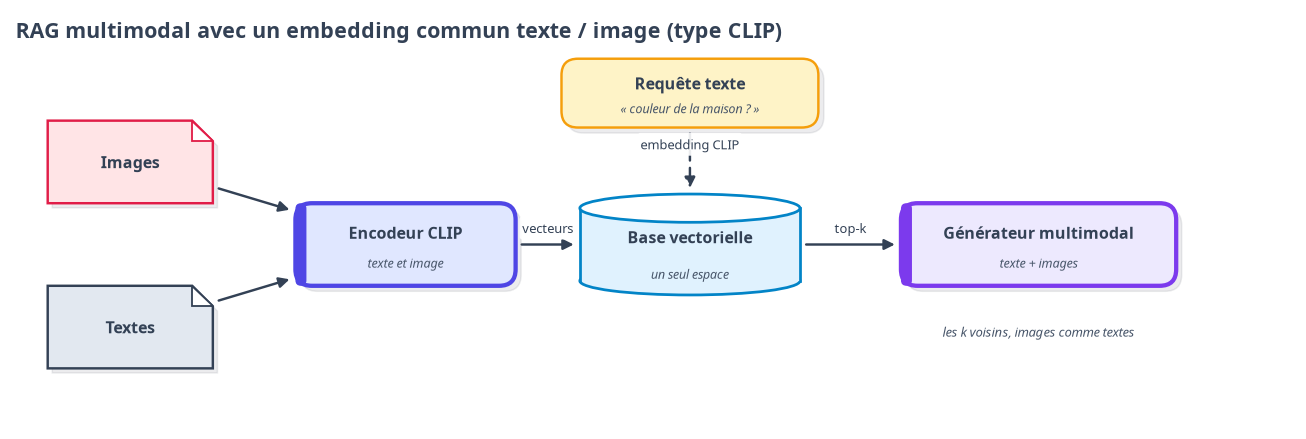

In [11]:
d = Diagram(14, 4.0, title="RAG multimodal avec un embedding commun texte / image (type CLIP)")
d.box("img", 1.3, 2.9, "Images", color=ROSE, kind="doc", w=1.8, h=0.9)
d.box("txt", 1.3, 1.1, "Textes", color=SLATE, kind="doc", w=1.8, h=0.9)
d.box("clip", 4.3, 2.0, "Encodeur CLIP", sub="texte et image", color=INDIGO, kind="model", w=2.4)
d.box("vdb", 7.4, 2.0, "Base vectorielle", sub="un seul espace", color=SKY, kind="db", w=2.4, h=1.1)
d.box("q", 7.4, 3.65, "Requête texte", sub="« couleur de la maison ? »", color=AMBER, w=2.8, h=0.75)
d.box("mm", 11.2, 2.0, "Générateur multimodal", sub="texte + images", color=VIOLET, kind="model", w=3.0)
d.arrow("img", "clip"); d.arrow("txt", "clip"); d.arrow("clip", "vdb", "vecteurs")
d.arrow("q", "vdb", "embedding CLIP", style="dashed"); d.arrow("vdb", "mm", "top-k")
d.note(11.2, 1.05, "les k voisins, images comme textes", fontsize=8.5)
d.show()

Le fonctionnement est identique au RAG textuel : (1) encoder toutes les données, textes et
images, avec CLIP ; (2) encoder la requête ; (3) chercher les plus proches voisins, quelle que
soit leur modalité.

> **À retenir.** Changer de modalité ne change pas le principe du RAG : il faut seulement un
> espace d'embedding commun (ou des métadonnées textuelles) et un générateur capable de lire
> ce qu'on lui donne.

## Synthèse

- Un RAG complet assemble recherche hybride, reranking, prompt et génération. Sur des faits
  absents des données d'entraînement, il fait passer l'exactitude d'un petit modèle de
  presque rien à une large majorité de réponses justes.
- Il faut mesurer aussi l'**abstention** face à un contexte hors sujet, et croiser qualité
  de la recherche et qualité de la réponse pour savoir quel composant améliorer.
- $k$ se choisit par la mesure : au-delà de la saturation du rappel, plus de passages coûtent
  plus cher sans aider.
- Au-delà du texte : **text-to-SQL** pour les tables (où un modèle un peu plus gros fait une
  vraie différence) et embeddings multimodaux pour les images.

**Liens.** Juges et métriques de génération : chapitres 3 et 4. Défense contre les injections
(requêtes SQL générées, documents malveillants) : chapitre 5. Affiner retriever et générateur :
chapitre 7. Latence et coût de la génération : chapitre 9.

In [12]:
c6.free_models()